# Space-charge prefill: Python vs MATLAB

Compare the saved independent prefill calculations:

1. Run `spacecharge_prefill_test.ipynb`.
2. Run all sections of `spacecharge_prefill_test.mlx`.
3. **Restart Kernel and Run All** here.

This notebook only reads result files. It does not calculate either field, start MATLAB, or overwrite files. Rerun both producers after changing inputs; matching case labels and the exported controls are not complete input fingerprints.


In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import Markdown, display

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "4.spacecharge_prefll_test"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})


## 1. Load saved results

Complex values, harmonic columns and empty source-array dimensions are retained. File modification times help identify stale outputs but do not prove identical inputs.


In [2]:
python_file = test_directory / "python_results.mat"
matlab_file = test_directory / "matlab_results.mat"
for result_file in (python_file, matlab_file):
    if not result_file.is_file():
        raise FileNotFoundError(f"Missing {result_file}. Run both prefill tests first.")
    modified = datetime.fromtimestamp(result_file.stat().st_mtime)
    print(f"{result_file.name}: {result_file}")
    print(f"  Last modified (local time): {modified:%Y-%m-%d %H:%M:%S}")

python_results = loadmat(python_file)
matlab_results = loadmat(matlab_file)


python_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\4.spacecharge_prefll_test\python_results.mat
  Last modified (local time): 2026-10-15 18:33:57
matlab_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\4.spacecharge_prefll_test\matlab_results.mat
  Last modified (local time): 2026-10-15 18:35:16


## 2. Comparison rules

Check all **23 calculated quantities**, six test settings, and the case label.

- `QQ` has `Ns` columns; `zp, gamazp, QQfill, Esz00` have `Ns+1` columns, including DC.
- Source matrices have `Nfill` rows; field matrices have one row per solver node.
- Expected empty source matrices must retain shape `(0, Ns+1)`. They pass only as empty matrices of that exact shape; the field must still be present on every solver node.
- Preserve complex signs/phases. Never compare magnitudes alone or flatten matrices.
- Row/column orientation may differ only for declared vectors.
- Counts and the four exported control settings match exactly. Floating-point calculations use the same per-entry absolute-plus-relative tolerance as previous tests.
- Missing, nonfinite, malformed or unexpected extra outputs prevent a pass.

When a gate is zero, `zp/gamazp/QQfill` in the MATLAB test are explicitly added diagnostics, not outputs created by the original disabled branch. The zero `Esz00` remains the original solver result.

**Known original limitation:** enabled `dN=1` changes MATLAB's implicit summation dimension, mixing the harmonics. This is an expected discrepancy, not a reason to relax tolerances. MATLAB's own DC check can stop before export in this case; do not compare an older result file as if it belonged to the failed run.


In [3]:
rtol = 1e-10
atol = 1e-12

# Name: (expected structure, units)
variables = {
    "Iz0": ("scalar", "A"), "I0": ("scalar", "A"), "U0": ("scalar", "kV"),
    "s": ("scalar", "1"), "vetoc": ("samples", "1"), "vn1": ("samples", "1"),
    "gama": ("scalar", "1"), "w": ("scalar", "rad/s"), "betae": ("scalar", "1/mm"),
    "dz": ("scalar", "mm"), "zi": ("nodes", "mm"), "z": ("nodes", "1"), "dt": ("scalar", "1"),
    "dN": ("count", "sources"), "QQDC": ("nodes", "1"), "QQ": ("harmonics", "1 (complex)"),
    "gamaz": ("nodes", "1"), "wp": ("scalar", "rad/s"),
    "zp": ("sources", "1"), "gamazp": ("sources", "1"),
    "QQfill": ("sources", "1 (complex)"), "Esz00": ("field", "1 (complex)"),
    "Nfill": ("count", "sources"), "Nt": ("count", "samples"), "Ns": ("count", "harmonics"),
    "factor": ("setting", "1"), "factorregion": ("setting", "1"),
    "fillfactor": ("setting", "1"), "DCSPfactor": ("setting", "1"),
}
matrix_structures = ("harmonics", "sources", "field")
complex_variables = ("QQ", "QQfill", "Esz00")

def get_count(results, name):
    values = results.get(name, np.array([]))
    if values.shape != (1, 1) or values.dtype.kind not in "iuf":
        return -1
    value = values.item()
    return int(value) if np.isfinite(value) and value >= 0 and value == np.floor(value) else -1


In [4]:
python_case = python_results.get("case_name", np.array([]))
matlab_case = matlab_results.get("case_name", np.array([]))
python_case = python_case.item() if python_case.size == 1 and python_case.dtype.kind in "US" else ""
matlab_case = matlab_case.item() if matlab_case.size == 1 and matlab_case.dtype.kind in "US" else ""
case_matches = bool(python_case) and python_case == matlab_case

comparison = []
pairs = {}  # Validated copies for plotting; saved arrays remain unchanged.
for name, (structure, units) in variables.items():
    python_values = python_results.get(name)
    matlab_values = matlab_results.get(name)
    row = {
        "name": name, "units": units,
        "python_shape": None if python_values is None else python_values.shape,
        "matlab_shape": None if matlab_values is None else matlab_values.shape,
        "max_absolute": None, "max_relative": None,
        "status": "NOT TESTED", "note": "",
    }
    comparison.append(row)
    if python_values is None or matlab_values is None:
        row["note"] = "Missing variable in one or both result files."
        continue

    allowed_types = "iufc" if name in complex_variables else "iuf"
    if any(values.dtype.kind not in allowed_types for values in (python_values, matlab_values)):
        row["note"] = "Unexpected data type."
        continue

    shape_ok = True
    for values, results in ((python_values, python_results), (matlab_values, matlab_results)):
        node_count = results.get("zi", np.array([])).size
        if structure in ("scalar", "count", "setting"):
            shape_ok = shape_ok and values.shape == (1, 1)
        elif structure in matrix_structures:
            Ns = get_count(results, "Ns")
            Nfill = get_count(results, "Nfill")
            rows = Nfill if structure == "sources" else node_count
            columns = Ns if structure == "harmonics" else Ns + 1
            shape_ok = shape_ok and node_count >= 2 and Ns >= 1 and Nfill >= 0
            shape_ok = shape_ok and values.shape == (rows, columns)
        else:
            expected_size = get_count(results, "Nt") if structure == "samples" else node_count
            shape_ok = shape_ok and values.ndim == 2 and 1 in values.shape
            shape_ok = shape_ok and expected_size >= 2 and values.size == expected_size

    if not shape_ok:
        row["note"] = f"Unexpected {structure} dimensions."
        continue

    # Do not discard imaginary parts: their signs encode the harmonic phases.
    dtype = complex if name in complex_variables else float
    python_values = python_values.astype(dtype)
    matlab_values = matlab_values.astype(dtype)
    if structure not in matrix_structures:
        python_values = python_values.reshape(-1)
        matlab_values = matlab_values.reshape(-1)
    if python_values.shape != matlab_values.shape:
        row["note"] = "Different dimensions after allowed vector-orientation adjustment."
        continue
    if not (np.all(np.isfinite(python_values)) and np.all(np.isfinite(matlab_values))):
        row["note"] = "NaN or infinity found."
        continue
    minimum_count = 1 if name in ("Nt", "Ns") else 0
    if structure == "count" and any(get_count(results, name) < minimum_count for results in (python_results, matlab_results)):
        row["note"] = "Counts must be integers in the permitted range."
        continue

    pairs[name] = (python_values, matlab_values)
    absolute_error = np.abs(python_values - matlab_values)
    row["max_absolute"] = np.max(absolute_error) if absolute_error.size else 0.0
    nonzero = matlab_values != 0
    if np.any(nonzero):
        row["max_relative"] = np.max(absolute_error[nonzero] / np.abs(matlab_values[nonzero]))
    if structure in ("count", "setting"):
        passed = np.array_equal(python_values, matlab_values)
        row["note"] = "Exact values"
    else:
        passed = np.all(absolute_error <= atol + rtol * np.abs(matlab_values))
        row["note"] = "Absolute + relative tolerance"
    row["status"] = "PASS" if passed else "FAIL"

exported_names = {
    name for results in (python_results, matlab_results)
    for name in results if not name.startswith("__")
}
extra_names = sorted(exported_names - variables.keys() - {"case_name"})
all_passed = case_matches and all(row["status"] == "PASS" for row in comparison) and not extra_names


## 3. Numerical summary

Maximum relative errors ignore zero MATLAB entries. Near-zero RF harmonics may have large relative errors while the absolute error is only roundoff. Expected empty arrays have maximum absolute difference zero and no relative-error value. No tolerance is relaxed for the field or for complex phases.


In [5]:
def format_error(value):
    return "-" if value is None else f"{value:.3e}"

table = [
    "| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |",
    "|---|---|---|---|---|---|---|---|",
]
for row in comparison:
    table.append(
        f"| {row['name']} | {row['units']} | {row['python_shape']} | {row['matlab_shape']} "
        f"| {format_error(row['max_absolute'])} | {format_error(row['max_relative'])} "
        f"| {row['status']} | {row['note']} |"
    )
display(Markdown("\n".join(table)))
print(f"Cases: Python={python_case!r}; MATLAB={matlab_case!r}; match={case_matches}")
if extra_names:
    print("NOT TESTED: unexpected exported variables:", ", ".join(extra_names))
passed_count = sum(row["status"] == "PASS" for row in comparison)
print(f"Tolerance: rtol={rtol:g}, atol={atol:g}")
print(f"{passed_count}/{len(variables)} numerical outputs/metadata passed.")
print("Overall: PASS" if all_passed else "Overall: NOT PASSED — inspect the table above.")


| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |
|---|---|---|---|---|---|---|---|
| Iz0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| I0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| U0 | kV | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| s | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vetoc | 1 | (1, 128) | (1, 128) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vn1 | 1 | (1, 128) | (1, 128) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| gama | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| w | rad/s | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| betae | 1/mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dz | mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| zi | mm | (1, 3806) | (3806, 1) | 4.547e-13 | 2.334e-16 | PASS | Absolute + relative tolerance |
| z | 1 | (1, 3806) | (3806, 1) | 1.421e-14 | 2.343e-16 | PASS | Absolute + relative tolerance |
| dt | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dN | sources | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| QQDC | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| QQ | 1 (complex) | (3806, 8) | (3806, 8) | 1.205e-16 | 1.219e+00 | PASS | Absolute + relative tolerance |
| gamaz | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| wp | rad/s | (1, 1) | (1, 1) | 4.768e-07 | 1.278e-16 | PASS | Absolute + relative tolerance |
| zp | 1 | (52, 9) | (52, 9) | 8.882e-16 | 2.130e-16 | PASS | Absolute + relative tolerance |
| gamazp | 1 | (52, 9) | (52, 9) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| QQfill | 1 (complex) | (52, 9) | (52, 9) | 1.205e-16 | 1.219e+00 | PASS | Absolute + relative tolerance |
| Esz00 | 1 (complex) | (3806, 9) | (3806, 9) | 1.041e-17 | 1.333e+00 | PASS | Absolute + relative tolerance |
| Nfill | sources | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Nt | samples | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Ns | harmonics | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| factor | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| factorregion | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| fillfactor | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| DCSPfactor | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |

Cases: Python='uniform'; MATLAB='uniform'; match=True
Tolerance: rtol=1e-10, atol=1e-12
29/29 numerical outputs/metadata passed.
Overall: PASS


## 4. Prefill-field overlay and complex differences

Choose physical harmonic `k`: zero is DC. Both real and imaginary parts are compared, with a zoom near the entrance. The numerical checks above cover **every** target node and harmonic, including the far-downstream tail.


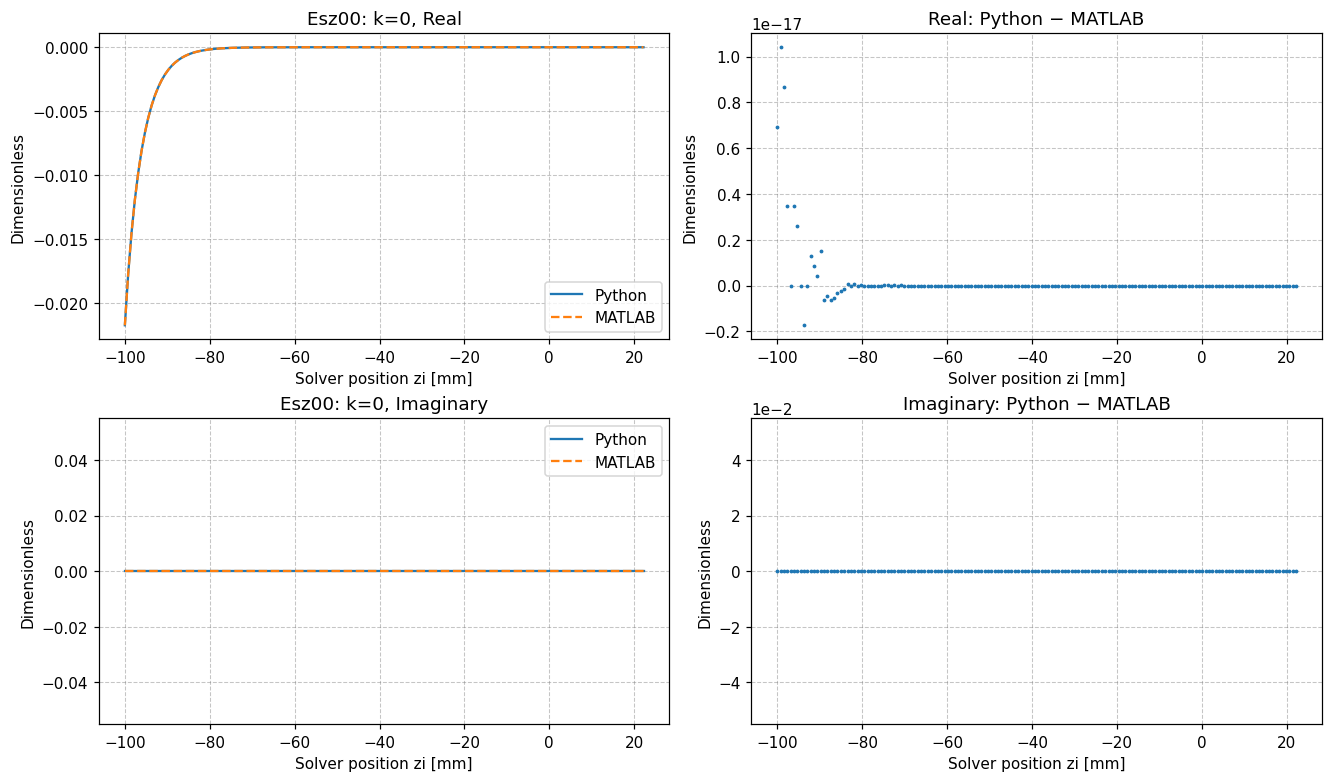

In [6]:
k = 0  # 0 = DC; choose 1..Ns after running a modulated case.
if "Esz00" in pairs and "zi" in pairs:
    python_field, matlab_field = pairs["Esz00"]
    assert 0 <= k < python_field.shape[1]
    python_z, matlab_z = pairs["zi"]
    dN = max(0, get_count(matlab_results, "dN"))
    stop = min(len(matlab_z), max(20, 3*dN))
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
    for row, (part, label) in enumerate(((np.real, "Real"), (np.imag, "Imaginary"))):
        left = part(python_field[:stop, k])
        right = part(matlab_field[:stop, k])
        axes[row, 0].plot(python_z[:stop], left, label="Python")
        axes[row, 0].plot(matlab_z[:stop], right, "--", label="MATLAB")
        axes[row, 0].set_title(f"Esz00: k={k}, {label}")
        axes[row, 0].legend()
        axes[row, 1].plot(matlab_z[:stop], left-right, ".", markersize=3)
        axes[row, 1].set_title(f"{label}: Python − MATLAB")
        axes[row, 1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useOffset=False)
    for ax in axes.flat:
        ax.set(xlabel="Solver position zi [mm]", ylabel="Dimensionless")
    plt.show()
else:
    print("Field plots unavailable: inspect the numerical summary.")


## 5. Upstream source phases

Choose a source harmonic to see both components of `QQfill`. Coordinates on this plot are the **normalized** stored `zp`, in nearest-to-farthest row order. No sorting or reinterpolation is performed in the comparison.


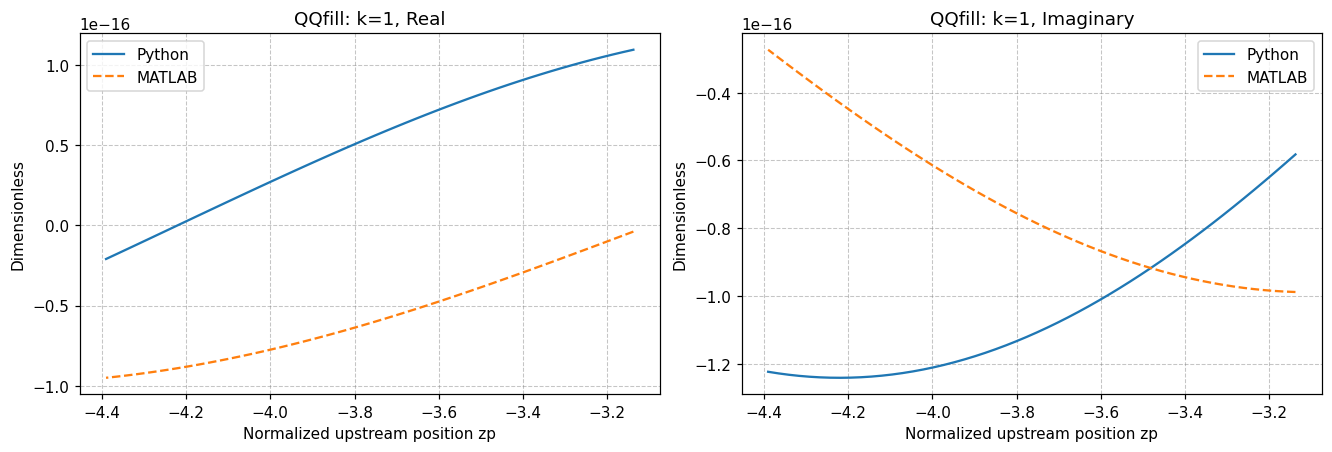

In [12]:
k = 1
if "QQfill" in pairs and "zp" in pairs:
    left, right = pairs["QQfill"]
    assert 0 <= k < left.shape[1]
    if left.shape[0]:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
        for ax, part, label in zip(axes, (np.real, np.imag), ("Real", "Imaginary")):
            ax.plot(pairs["zp"][0][:, 0], part(left[:, k]), label="Python")
            ax.plot(pairs["zp"][1][:, 0], part(right[:, k]), "--", label="MATLAB")
            ax.set(xlabel="Normalized upstream position zp", ylabel="Dimensionless",
                   title=f"QQfill: k={k}, {label}")
            ax.legend()
        plt.show()
    else:
        print("No source curves: both QQfill arrays have the expected empty shape.")
else:
    print("Source plots unavailable: inspect the numerical summary.")


## 6. Per-harmonic errors and final result

Each error is the maximum complex absolute difference over all relevant rows. This tests the fixed upstream contribution only, not the later global/local space-charge update or total electric field.


In [8]:
if "Esz00" in pairs and "QQfill" in pairs:
    field_error = np.max(np.abs(pairs["Esz00"][0] - pairs["Esz00"][1]), axis=0)
    source_difference = np.abs(pairs["QQfill"][0] - pairs["QQfill"][1])
    source_error = np.max(source_difference, axis=0) if source_difference.shape[0] else np.zeros(len(field_error))
    table = ["| Harmonic | Max QQfill error | Max Esz00 error |", "|---|---|---|"]
    for k in range(len(field_error)):
        table.append(f"| {k} | {source_error[k]:.3e} | {field_error[k]:.3e} |")
    display(Markdown("\n".join(table)))
assert all_passed, "Prefill comparison did not pass. Review the numerical summary."
print("PASS: all 23 calculated quantities, six test settings, and the case label agree.")


| Harmonic | Max QQfill error | Max Esz00 error |
|---|---|---|
| 0 | 0.000e+00 | 1.041e-17 |
| 1 | 1.205e-16 | 1.856e-18 |
| 2 | 8.345e-18 | 1.269e-19 |
| 3 | 4.870e-17 | 7.250e-19 |
| 4 | 1.214e-17 | 1.758e-19 |
| 5 | 3.400e-17 | 4.760e-19 |
| 6 | 4.337e-18 | 5.844e-20 |
| 7 | 2.098e-17 | 2.712e-19 |
| 8 | 4.888e-18 | 6.050e-20 |

PASS: all 23 calculated quantities, six test settings, and the case label agree.
